## Load the data

In [1]:
import json
import numpy as np

with open("tallinn_osrm_matrix.json", "r", encoding="utf-8") as f:
    data = json.load(f)

# Number of locations, including depot
n = 5

# Location names
names = [point["name"] for point in data["points"][:n]]

# Distance matrix in kilometres
distances = np.array(data["distances"], dtype=float)[:n, :n] / 1000

print("Locations:")
for i, name in enumerate(names):
    print(f"{i}: {name}")

print("\nDistance matrix (km):")
print(np.round(distances, 2))

Locations:
0: Omniva Pallasti (depot)
1: Kadriorg President's Office
2: Shaurma Kebab Punane
3: Kultuurikatel
4: Patarei Prison

Distance matrix (km):
[[0.   2.68 2.77 3.94 5.14]
 [2.91 0.   4.47 3.22 4.42]
 [2.75 5.21 0.   6.13 7.33]
 [4.22 3.48 6.83 0.   1.39]
 [5.16 4.42 7.77 1.62 0.  ]]


## Optimal route with classical algorithm

In [2]:
from itertools import permutations

def calculate_distance(route, distances):
    return sum(
        distances[route[i], route[i + 1]]
        for i in range(len(route) - 1)
    )

best_distance = float("inf")
best_route = None

# Depot (0) is fixed at the start and end
for order in permutations(range(1, n)):
    route = (0,) + order + (0,)

    total_distance = calculate_distance(route, distances)

    if total_distance < best_distance:
        best_distance = total_distance
        best_route = route

print("Optimal route:")
print(" → ".join(names[i] for i in best_route))

print(f"\nMinimum distance: {best_distance:.2f} km")

Optimal route:
Omniva Pallasti (depot) → Kultuurikatel → Patarei Prison → Kadriorg President's Office → Shaurma Kebab Punane → Omniva Pallasti (depot)

Minimum distance: 16.96 km


## Visualization

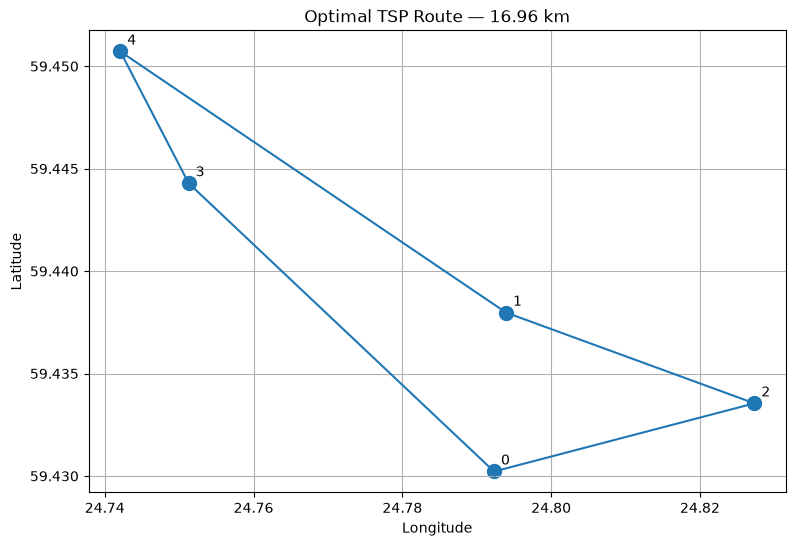

In [3]:
import matplotlib.pyplot as plt

# Coordinates of selected locations
latitudes = [p["lat"] for p in data["points"][:n]]
longitudes = [p["lon"] for p in data["points"][:n]]

plt.figure(figsize=(9, 6))

# Draw locations
plt.scatter(longitudes, latitudes, s=100)

# Draw route
route_lons = [longitudes[i] for i in best_route]
route_lats = [latitudes[i] for i in best_route]

plt.plot(route_lons, route_lats, marker="o")

for i, name in enumerate(names):
    plt.annotate(str(i), (longitudes[i], latitudes[i]),
                 xytext=(5, 5), textcoords="offset points")

plt.title(f"Optimal TSP Route — {best_distance:.2f} km")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.grid(True)
plt.show()